=== 📊 نرخ ریزش کل (Churn Rate %) ===
Churn
No     72.4
Yes    27.6
Name: proportion, dtype: float64

=== 📜 ریزش به تفکیک نوع قرارداد (%) ===
Churn              No    Yes
Contract                    
Month-to-Month  71.66  28.34
One-Year        74.51  25.49
Two-Year        71.01  28.99


C:\Users\soheil\AppData\Local\Temp\ipykernel_9948\365240969.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df_churn, x='Churn', y='MonthlyCharges', palette='Set2')


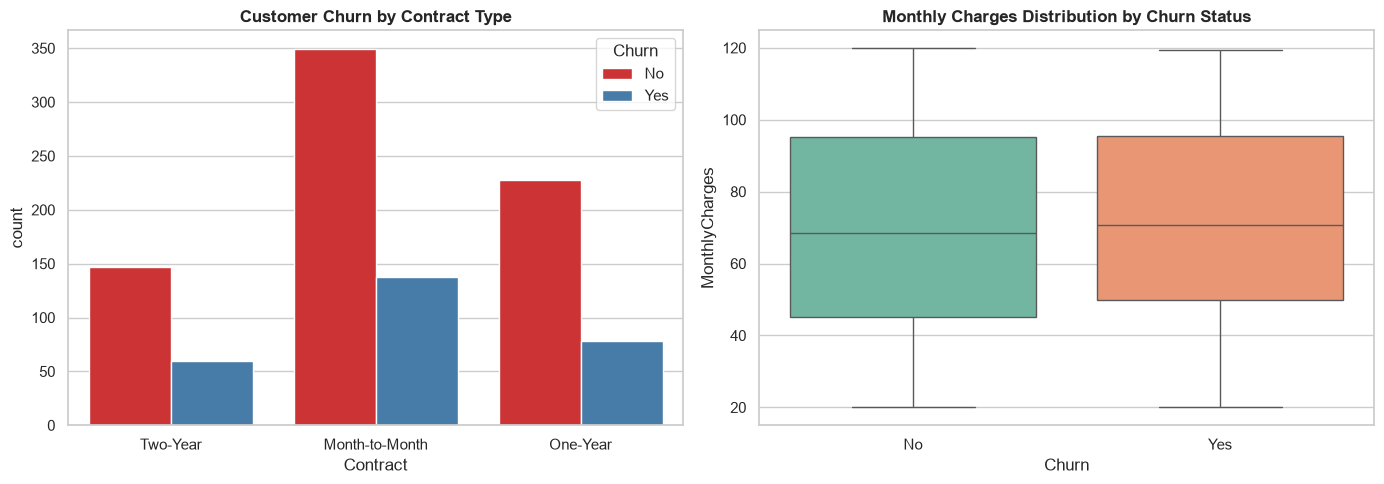

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


np.random.seed(42)
n = 1000

df_churn = pd.DataFrame({
    'CustomerID': [f'TEL-{1000+i}' for i in range(n)],
    'Tenure_Months': np.random.randint(1, 72, size=n),
    'Contract': np.random.choice(['Month-to-Month', 'One-Year', 'Two-Year'], size=n, p=[0.5, 0.3, 0.2]),
    'MonthlyCharges': np.random.uniform(20, 120, size=n).round(2),
    'Churn': np.random.choice(['Yes', 'No'], size=n, p=[0.27, 0.73])
})


churn_rate = (df_churn['Churn'].value_counts(normalize=True) * 100).round(2)
contract_churn = pd.crosstab(df_churn['Contract'], df_churn['Churn'], normalize='index') * 100

print("=== 📊 نرخ ریزش کل (Churn Rate %) ===")
print(churn_rate)
print("\n=== 📜 ریزش به تفکیک نوع قرارداد (%) ===")
print(contract_churn.round(2))


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.countplot(ax=axes[0], data=df_churn, x='Contract', hue='Churn', palette='Set1')
axes[0].set_title('Customer Churn by Contract Type', fontsize=12, fontweight='bold')


sns.boxplot(ax=axes[1], data=df_churn, x='Churn', y='MonthlyCharges', palette='Set2')
axes[1].set_title('Monthly Charges Distribution by Churn Status', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()